# 7.4 — Hyperparameter Tuning

**Thursday · Full-time Data Analytics · notebook**

**Learning goals**
- Distinguish learned parameters from hyperparameters.
- Explain why using the test set to choose hyperparameters biases evaluation.
- Compare a fixed validation split with K-fold cross-validation.
- Tune a complete scikit-learn `Pipeline` using `GridSearchCV` and `RandomizedSearchCV`.
- Understand `refit=True` and evaluate the selected pipeline once on untouched test data.

**Estimated time:** ~90–100 minutes. The afternoon lab uses **Grid Search** on Spaceship Titanic; this notebook uses regression on California Housing to keep the examples focused.

## 1. Parameters vs. hyperparameters

Think of a **car model**: different versions may have different engines or suspensions, and their performance varies with driving conditions. Likewise, we choose an algorithm and configure its **hyperparameters** before fitting it to data. During `fit()`, the algorithm **learns parameters** from the training examples.

| Estimator | Learned parameters | Hyperparameters |
|---|---|---|
| `LinearRegression` | `coef_`, `intercept_` | `fit_intercept` |
| `LogisticRegression` | `coef_`, `intercept_` | `C`, `max_iter` |
| `DecisionTreeRegressor` | Split features, thresholds, leaf predictions | `max_depth`, `min_samples_leaf` |
| `RandomForestRegressor` | Fitted trees and their splits | `n_estimators`, `max_depth` |

**Crucial:** linear and logistic regression **coefficients are parameters, not hyperparameters**. We do not provide their values in a search grid: the estimator learns them during fitting. Hyperparameters can control model complexity *or* the optimization procedure (e.g., `max_iter`).

**Check for understanding:** Is `model__max_depth` a learned parameter or a hyperparameter? What about `coef_`?

## 2. Why a separate validation set?

Suppose we try 100 hyperparameter combinations and pick the one with the highest **test score**. Even if the test observations were never used in `.fit()`, their scores **influenced our choice**. The winning score is therefore typically **optimistically biased**: we selected a configuration partly because it happened to perform well on this particular test sample.

**Rule:** reserve the test set for a final evaluation after all model-selection decisions are made. A test score is still an **estimate**: another independent sample might produce a different result.

### Strategy A — Fixed train / validation / test split

Fit on **train**, select hyperparameters on **validation**, and evaluate once on **test**. After selecting the configuration, we can refit on **train + validation** before the final test evaluation. The selected hyperparameters depend partly on which observations landed in the validation set.

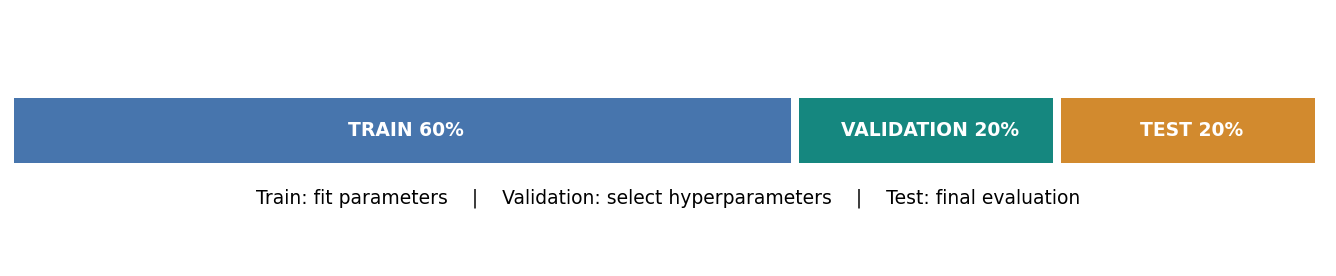

### Strategy B — K-fold cross-validation within the training set

A more data-efficient alternative is to split the dataset into **training and test only**, then repeatedly create training/validation folds **inside the training set**. Every training observation serves as validation once in ordinary K-fold CV.

If you previously named two fixed subsets *train* and *validation*, CV can operate on their **combined data**. There is no permanent validation subset: the folds take turns. The **test set remains untouched**.

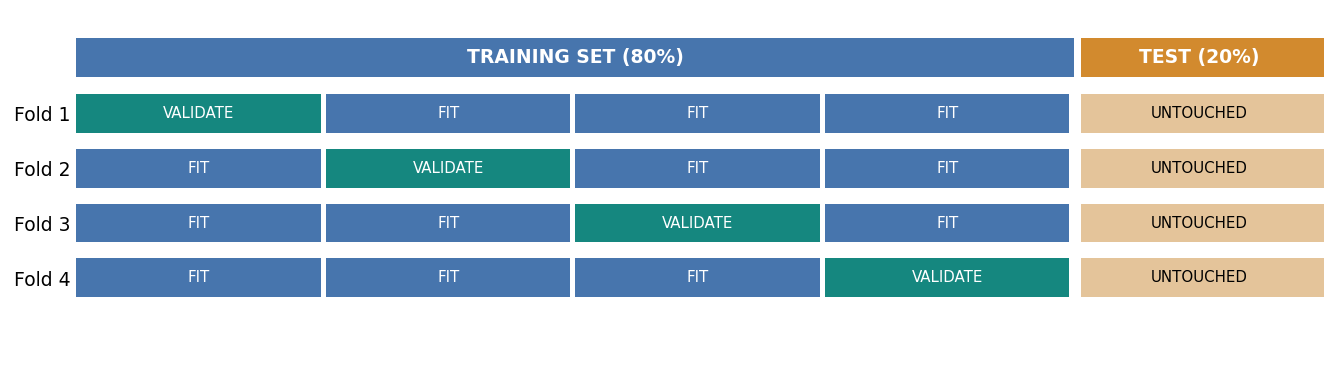

## 3. Dataset and a baseline pipeline

We use California Housing, as in Wednesday's regression examples. For a fast, consistent comparison we select the same five features and retain an untouched 20% test set.

Tree-based models do not require feature scaling, but we still use an explicit `Pipeline` to keep preprocessing and modeling as a single object. This becomes essential when preprocessing must be learned inside each CV fold.

In [ ]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, r2_score

RANDOM_STATE = 42
FEATURES = ["MedInc", "HouseAge", "AveRooms", "Latitude", "Longitude"]

housing = fetch_california_housing(as_frame=True)
X = housing.frame[FEATURES]
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

baseline = Pipeline([
    ("model", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))
])
baseline.fit(X_train, y_train)

baseline_train_predictions = baseline.predict(X_train)
print(f"Baseline training MAE (not a generalization estimate): "
      f"{mean_absolute_error(y_train, baseline_train_predictions):.3f}")

The baseline training score is shown only as a starting point; it is **not** an unbiased estimate of generalization performance. We keep the test set untouched until the final evaluation. Hyperparameter selection uses cross-validation on the training set.

## 4. GridSearchCV — systematic search

`GridSearchCV` tries **every combination** in a specified grid. For each combination, it fits a fresh pipeline on the training folds and scores it on the validation fold. The best configuration is selected by its **mean CV score**.

With `Pipeline`, write `step_name__hyperparameter`: here `model__max_depth`.

We choose small, illustrative ranges; there are no universally best ranges. A deeper tree can fit more complex patterns but may overfit. Larger `min_samples_leaf` values regularize a tree by requiring more samples in each leaf.

In [ ]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
])

param_grid = {
    "model__max_depth": [3, 5, 8, 12],
    "model__min_samples_leaf": [1, 5, 15],
}

# 4 depths × 3 leaf sizes = 12 configurations; 4 folds = 48 CV fits.
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=4,
    refit=True,
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

print("Best hyperparameters:", grid_search.best_params_)
print(f"Best mean CV MAE: {-grid_search.best_score_:.3f}")

### What does `refit=True` do?

After CV selects the best hyperparameters, `GridSearchCV` **automatically fits a new copy of the complete winning pipeline on all of `X_train, y_train`**. The fitted pipeline is available as `best_estimator_`.

- `best_params_`: selected hyperparameter values.
- `best_score_`: mean **validation-fold** score of the winning configuration (not a test score).
- `cv_results_`: scores for all tested configurations.
- `best_estimator_`: pipeline refitted on the **entire training set**.

The negative sign in `neg_mean_absolute_error` lets scikit-learn **maximize** a score even though lower MAE is better. Multiply by −1 to display a conventional positive MAE.

**Important:** `refit=True` does **not** fit on test data, and we do not call `.fit()` again on `best_estimator_`.

In [ ]:
results = pd.DataFrame(grid_search.cv_results_)
summary = results[[
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "mean_test_score",  # sklearn calls the held-out CV fold "test" here.
    "std_test_score",
    "rank_test_score",
]].copy()
summary["cv_mae"] = -summary["mean_test_score"]
summary.sort_values("rank_test_score").head(8)

**Naming trap:** the `mean_test_score` column in `cv_results_` refers to **held-out validation folds inside CV**, not our external `X_test`. This is historical scikit-learn terminology.

**Quick question:** Why is the best mean CV score not a completely independent estimate of the entire tuning procedure's performance? Because we selected the *maximum* among many noisy CV estimates. We will study more rigorous evaluation in the self-learning notebook.

## 5. RandomizedSearchCV — sample configurations

`RandomizedSearchCV` samples a specified number of configurations instead of testing every possible combination. It is especially useful when there are many hyperparameters or wide ranges. With lists, it samples candidate values; distributions allow broader numerical exploration.

**For a fair classroom comparison**, we keep the same CV folds and scoring metric. We will compare the *search procedures* using their training CV results—not select a winner by repeatedly checking test scores.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions={
        "model__max_depth": randint(2, 16),
        "model__min_samples_leaf": randint(1, 21),
    },
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=4,
    refit=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
random_search.fit(X_train, y_train)

comparison = pd.DataFrame({
    "Search": ["GridSearchCV", "RandomizedSearchCV"],
    "Best CV MAE": [-grid_search.best_score_, -random_search.best_score_],
    "Configurations tried": [len(grid_search.cv_results_["params"]),
                             len(random_search.cv_results_["params"])],
})
comparison

**Discussion (2 minutes):** Is Random Search guaranteed to win? No. Is Grid Search guaranteed to find the best possible hyperparameters? Only within its **specified finite grid**. Both approaches depend on the search space and the CV split.

**Practical search-space advice:** start with a manageable range; inspect CV results; refine the range only using training data. `max_depth`, `min_samples_leaf`, `n_estimators`, and `C` have different meanings and scales—avoid applying one generic numerical range to all of them.

## 6. Keep the test set untouched until the end

We have used cross-validation **inside the training set** to compare hyperparameter configurations. `grid_search.best_estimator_` is already refitted on all training data because `refit=True`.

We could now evaluate it on `X_test`, but in the guided practice we will also compare **two model families**. Therefore, we postpone the final test evaluation until **after** both the hyperparameters **and the model family** have been selected using cross-validation. Otherwise, the test set would influence our decisions.


In [ ]:
# The best pipeline from the demonstration is already fitted.
# We deliberately do NOT evaluate it on X_test yet.
print("Best Decision Tree CV MAE:", round(-grid_search.best_score_, 3))
print("Refitted pipeline:", grid_search.best_estimator_)


## 7. Guided practice — tune and compare two ensemble models

**Goal (about 15–25 minutes, depending on runtime):** compare a **Random Forest** (bagging-based) and a **Gradient Boosting** regressor (boosting-based) using the same California Housing training data.

Both methods use decision trees, but they combine them differently: Random Forest fits many trees with randomness and aggregates their predictions; Gradient Boosting adds trees sequentially to correct errors.

**Your tasks**

1. Inspect the two provided pipelines and **choose the values** for each bounded parameter grid.
2. Run `GridSearchCV` for each model using **exactly 4 folds**, the same scoring metric, and `refit=True`.
3. Compare the **best cross-validation MAE** and select the winning model **without consulting the test set**.
4. Evaluate the selected, refitted pipeline **once** on the untouched test set.

**Search limits — keep this exercise manageable**

| Model | Hyperparameter | Allowed values / range | Why it matters |
|---|---|---|---|
| Random Forest | `n_estimators` | **30–100**, integers | Number of trees; affects stability and runtime |
| Random Forest | `max_depth` | **3–12**, integers; **no `None`** | Controls tree complexity and training time |
| Gradient Boosting | `n_estimators` | **30–100**, integers | Number of boosting stages |
| Gradient Boosting | `learning_rate` | **0.05–0.20** | Contribution of each new tree |

Choose **exactly 2 different values per hyperparameter**, within the allowed ranges. This gives **4 combinations per model**. Keep all other hyperparameters at the values provided. Do **not** add extra parameters to tune. Avoid `max_depth=None`.

With 4 folds and 4 combinations per model, you will run **16 CV fits per model**, plus one automatic refit each: **34 model fits in total**. Runtime will depend on the environment.

**Important:** `refit=True` automatically fits each model's winning pipeline on **all of `X_train`**. Do not call `.fit()` again on the winner.


In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Step 1 — Define two different ensemble strategies.
candidates = {
    "Random Forest": Pipeline([
        ("model", RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("model", GradientBoostingRegressor(
            random_state=RANDOM_STATE,
            max_depth=2,  # Fixed: keep individual boosting trees shallow.
        ))
    ]),
}

# Step 2 — Choose exactly TWO values for each hyperparameter.
# Stay within the ranges in the table above. Do not use max_depth=None.
# Replace each TODO with a valid value before running the next cell.
# Each model should have 2 x 2 = 4 combinations.
parameter_grids = {
    "Random Forest": {
        "model__n_estimators": [TODO, TODO],  # Integers from 30 to 100
        "model__max_depth": [TODO, TODO],      # Integers from 3 to 12
    },
    "Gradient Boosting": {
        "model__n_estimators": [TODO, TODO],  # Integers from 30 to 100
        "model__learning_rate": [TODO, TODO], # Numbers from 0.05 to 0.20
    },
}


In [ ]:
# Step 3 — Tune each pipeline on the TRAINING set only.
# TODO: uncomment the two indicated lines to run the searches.
searches = {}

for name, candidate_pipeline in candidates.items():
    search = GridSearchCV(
        estimator=candidate_pipeline,
        param_grid=parameter_grids[name],
        scoring="neg_mean_absolute_error",
        cv=4,
        refit=True,
        n_jobs=1,  # Avoid nested parallelism (Random Forest uses n_jobs=-1).
    )
    # search.fit(X_train, y_train)
    # searches[name] = search

# Step 4 — Compare best CV scores (lower MAE is better).
# TODO: uncomment after running the searches.
# cv_comparison = pd.DataFrame([
#     {"Model": name, "Best CV MAE": -search.best_score_,
#      "Best parameters": search.best_params_}
#     for name, search in searches.items()
# ]).sort_values("Best CV MAE")
# display(cv_comparison)


In [ ]:
# Step 5 — Select using CV results, then evaluate ONCE on test.
# TODO: uncomment after completing Step 4.
# winner_name = cv_comparison.iloc[0]["Model"]
# winner_pipeline = searches[winner_name].best_estimator_
# final_predictions = winner_pipeline.predict(X_test)
#
# print("Selected model:", winner_name)
# print(f"Final test MAE: {mean_absolute_error(y_test, final_predictions):.3f}")
# print(f"Final test R²:  {r2_score(y_test, final_predictions):.3f}")


**Check for understanding**

- How does Random Forest differ from Gradient Boosting in the way it combines trees?
- Why do we select the winner using cross-validation scores instead of test scores?
- Why have we bounded `max_depth`, `n_estimators`, and `learning_rate`?
- What does `refit=True` do for **each** search?
- Would it be valid to modify the grids after inspecting the final test result and report only the best test score? Why not?

### Bridge to the afternoon lab — Spaceship Titanic

The lab uses **classification**. Reuse your earlier preprocessing and classifier in a pipeline; replace the regression metric with a suitable classification metric (such as `accuracy` or `f1`). Use `model__...` parameter names that match your chosen classifier. Fit learned preprocessing *inside* cross-validation, and remember that the lab specifically requests **Grid Search**.


## Recap — check for understanding

1. Why are `LinearRegression.coef_` and `LogisticRegression.coef_` **not** hyperparameters?
2. Why does choosing a configuration using the test set make its reported test performance optimistic?
3. With 4-fold CV, where do the validation folds come from? What happens to the external test set?
4. What does `model__max_depth` mean inside a pipeline?
5. What exactly happens when `GridSearchCV(refit=True)` finishes?
6. Why are `best_score_` and the final test score different?

**Optional self-learning:** Optuna and adaptive search; performance uncertainty; nested and repeated nested cross-validation.

**Documentation:** [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) · [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) · [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)